In [2]:
import numpy as np
import matplotlib.pyplot as plt

from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(0)

print("Biblioteki zaimportowane")


Biblioteki zaimportowane


In [3]:
# Pilot samolotu
LOTNICTWO = [
    "Pilot sprawdza, czy samolot jest gotowy do lotu.",
    "Pilot wchodzi do kabiny, a kokpit jest już przygotowany.",
    "Pilot obserwuje pas startowy przed odlotem.",
    "Pilot czeka, aż lotnisko wyda zgodę na start.",
    "Pilot sprawdza przyrządy, gdy samolot stoi na ziemi.",
    "Pilot zajmuje miejsce, a kabina jest gotowa do podróży.",
    "Pilot obserwuje światła, gdy kokpit jest ciemny.",
    "Pilot widzi pas startowy podczas lądowania.",
    "Pilot informuje załogę, że samolot zaraz wystartuje.",
    "Pilot sprawdza pogodę, zanim lotnisko rozpocznie odprawę.",
    "Pilot kontroluje wysokość, a kokpit pokazuje parametry lotu.",
    "Pilot przygotowuje kabinę do długiej podróży.",
    "Pilot widzi, że pas startowy jest wolny.",
    "Pilot kieruje maszyną, gdy samolot przelatuje nad miastem.",
    "Pilot słucha komunikatów, które przekazuje lotnisko.",
    "Pilot obserwuje chmury, a kokpit pokazuje kierunek lotu.",
    "Pilot sprawdza, czy kabina jest odpowiednio oświetlona.",
    "Pilot czeka na sygnał, że pas startowy jest dostępny.",
    "Pilot zgłasza gotowość, kiedy samolot kończy przygotowania.",
    "Pilot kończy lot, gdy lotnisko przyjmuje lądującą maszynę."
]

# Pilot do telewizora
TELEWIZJA = [
    "Pilot leży na stole, a telewizor jest włączony.",
    "Pilot posiada przycisk, który zmienia kanał.",
    "Pilot działa poprawnie, gdy bateria jest naładowana.",
    "Pilot steruje urządzeniem, a ekran pokazuje obraz.",
    "Pilot włącza telewizor jednym kliknięciem.",
    "Pilot ma przycisk do regulacji głośności.",
    "Pilot wybiera kanał z ulubionym programem.",
    "Pilot przestaje działać, kiedy bateria jest rozładowana.",
    "Pilot zmienia ustawienia, które pokazuje ekran.",
    "Pilot pozwala wyłączyć telewizor bez wstawania.",
    "Pilot ma czerwony przycisk do wyłączania urządzenia.",
    "Pilot przełącza kanał podczas oglądania wiadomości.",
    "Pilot potrzebuje zasilania, gdy bateria jest słaba.",
    "Pilot wysyła sygnał, a ekran zmienia jasność.",
    "Pilot steruje dźwiękiem, gdy telewizor odtwarza film.",
    "Pilot posiada mały przycisk do otwierania menu.",
    "Pilot wybiera kanał sportowy podczas meczu.",
    "Pilot nie reaguje, ponieważ bateria wymaga wymiany.",
    "Pilot otwiera ustawienia, a ekran wyświetla dostępne opcje.",
    "Pilot uruchamia telewizor i rozpoczyna odtwarzanie filmu."
]

# Zdania neutralne
NEUTRALNE = [
    "Rano w parku świeci słońce.",
    "Wieczorem na ulicy zapalają się latarnie.",
    "Student czyta książkę w bibliotece.",
    "Nauczyciel tłumaczy zadanie podczas lekcji.",
    "W kuchni pachnie świeżym chlebem.",
    "Pociąg przyjeżdża na dworzec punktualnie.",
    "Zimą na chodniku leży biały śnieg.",
    "Latem dzieci bawią się na plaży.",
    "W ogrodzie rosną kolorowe kwiaty.",
    "Muzyk ćwiczy nową melodię na gitarze.",
    "Kucharz przygotowuje obiad dla rodziny.",
    "Fotograf robi zdjęcia podczas spaceru.",
    "Podróżnik planuje wycieczkę w góry.",
    "Sportowiec codziennie trenuje na stadionie.",
    "Lekarz rozmawia spokojnie z pacjentem.",
    "Uczeń zapisuje notatki w zeszycie.",
    "W centrum miasta otwarto nowy sklep.",
    "Wiatr porusza gałęzie wysokich drzew.",
    "Artysta maluje krajobraz farbami.",
    "Rodzina odpoczywa nad jeziorem w weekend."
]

# Normalizacja tekstu
LOTNICTWO = [s.lower() for s in LOTNICTWO]
TELEWIZJA = [s.lower() for s in TELEWIZJA]
NEUTRALNE = [s.lower() for s in NEUTRALNE]

KORPUS = LOTNICTWO + TELEWIZJA + NEUTRALNE

def slowa(s):
    return s.lower().replace(".", "").replace(",", "").split()

# Sprawdzenie danych
assert len(KORPUS) == 60
assert len(set(KORPUS)) == 60

for s in LOTNICTWO + TELEWIZJA:
    assert slowa(s).count("pilot") == 1

for s in NEUTRALNE:
    assert "pilot" not in slowa(s)

print("Źródło: zdania przygotowane na potrzeby ćwiczenia")
print("Lotnictwo:", len(LOTNICTWO))
print("Telewizja:", len(TELEWIZJA))
print("Neutralne:", len(NEUTRALNE))
print("Łącznie:", len(KORPUS))


Źródło: zdania przygotowane na potrzeby ćwiczenia
Lotnictwo: 20
Telewizja: 20
Neutralne: 20
Łącznie: 60


In [4]:
PARY = [
    ("pilot", "pilotem"),
    ("samolot", "samolotem"),
    ("kabina", "kabinami"),
    ("lotnisko", "lotniskami"),
    ("pas", "pasami"),
    ("ekran", "ekranem"),
    ("przycisk", "przyciskiem"),
    ("kanał", "kanałami"),
    ("telewizor", "telewizorami")
]

WIDZIANE = [a for a, b in PARY]
NIEWIDZIANE = [b for a, b in PARY]

slownik_korpusu = set(
    w for zdanie in KORPUS for w in slowa(zdanie)
)

print("Sprawdzenie form:\n")

for widziana, niewidziana in PARY:
    assert widziana in slownik_korpusu
    assert niewidziana not in slownik_korpusu

    print(
        f"{widziana:15s} - widziana | "
        f"{niewidziana:15s} - niewidziana"
    )


Sprawdzenie form:

pilot           - widziana | pilotem         - niewidziana
samolot         - widziana | samolotem       - niewidziana
kabina          - widziana | kabinami        - niewidziana
lotnisko        - widziana | lotniskami      - niewidziana
pas             - widziana | pasami          - niewidziana
ekran           - widziana | ekranem         - niewidziana
przycisk        - widziana | przyciskiem     - niewidziana
kanał           - widziana | kanałami        - niewidziana
telewizor       - widziana | telewizorami    - niewidziana


In [5]:
# Hipoteza:
# Większy słownik BPE powinien zmniejszać liczbę
# tokenów potrzebnych do zapisania słowa.

LIMITY = [80, 160, 320]
tokenizery = {}

for limit in LIMITY:

    tok = Tokenizer(
        models.BPE(unk_token="[UNK]")
    )

    tok.pre_tokenizer = pre_tokenizers.Whitespace()

    trener = trainers.BpeTrainer(
        vocab_size=limit,
        min_frequency=1,
        special_tokens=["[UNK]"]
    )

    tok.train_from_iterator(KORPUS, trainer=trener)

    tokenizery[limit] = tok

    print(
        f"Limit: {limit}, "
        f"faktyczny słownik: {tok.get_vocab_size()}"
    )

rozmiary = [
    tok.get_vocab_size() for tok in tokenizery.values()
]

assert len(set(rozmiary)) == 3


Limit: 80, faktyczny słownik: 80
Limit: 160, faktyczny słownik: 160
Limit: 320, faktyczny słownik: 320


In [6]:
def statystyki_bpe(tok, wyrazy):
    dlugosci = []
    liczba_unk = 0

    for w in wyrazy:
        tokeny = tok.encode(w).tokens
        dlugosci.append(len(tokeny))

        if "[UNK]" in tokeny:
            liczba_unk += 1

    return np.mean(dlugosci), liczba_unk


print("PORÓWNANIE TOKENIZACJI BPE\n")

print(
    f"{'Limit':>7} {'Słownik':>9} "
    f"{'Widziane':>11} {'UNK W':>7} "
    f"{'Niewidziane':>13} {'UNK N':>7}"
)

for limit, tok in tokenizery.items():

    sr_w, unk_w = statystyki_bpe(tok, WIDZIANE)
    sr_n, unk_n = statystyki_bpe(tok, NIEWIDZIANE)

    print(
        f"{limit:7d} "
        f"{tok.get_vocab_size():9d} "
        f"{sr_w:11.2f} {unk_w:7d} "
        f"{sr_n:13.2f} {unk_n:7d}"
    )


print("\nPODZIAŁ DWÓCH NIEWIDZIANYCH FORM\n")

for w in ["pilotem", "lotniskami"]:

    print(f"\nWyraz: {w}")

    for limit, tok in tokenizery.items():
        tokeny = tok.encode(w).tokens
        print(f"Limit {limit}: {tokeny}")


print("\nFRAGMENTY I ICH WYSTĘPOWANIE W KORPUSIE\n")

for w in ["pilotem", "lotniskami"]:

    print(f"\nWyraz: {w}")

    for limit, tok in tokenizery.items():
        print(f"Limit {limit}:")

        for fragment in tok.encode(w).tokens:
            if fragment == "[UNK]":
                continue

            przyklady = [
                x for x in sorted(slownik_korpusu)
                if fragment in x
            ]

            print(
                f"  {fragment:12s} -> {przyklady[:5]}"
            )


PORÓWNANIE TOKENIZACJI BPE

  Limit   Słownik    Widziane   UNK W   Niewidziane   UNK N
     80        80        3.67       0          5.67       0
    160       160        1.11       0          3.56       0
    320       320        1.00       0          3.44       0

PODZIAŁ DWÓCH NIEWIDZIANYCH FORM


Wyraz: pilotem
Limit 80: ['pilot', 'em']
Limit 160: ['pilot', 'em']
Limit 320: ['pilot', 'em']

Wyraz: lotniskami
Limit 80: ['lot', 'ni', 's', 'ka', 'm', 'i']
Limit 160: ['lotni', 's', 'ka', 'm', 'i']
Limit 320: ['lotni', 's', 'ka', 'm', 'i']

FRAGMENTY I ICH WYSTĘPOWANIE W KORPUSIE


Wyraz: pilotem
Limit 80:
  pilot        -> ['pilot']
  em           -> ['chlebem', 'ciemny', 'dźwiękiem', 'jeziorem', 'kliknięciem']
Limit 160:
  pilot        -> ['pilot']
  em           -> ['chlebem', 'ciemny', 'dźwiękiem', 'jeziorem', 'kliknięciem']
Limit 320:
  pilot        -> ['pilot']
  em           -> ['chlebem', 'ciemny', 'dźwiękiem', 'jeziorem', 'kliknięciem']

Wyraz: lotniskami
Limit 80:
  lot     

In [7]:
# Wariant A - więcej zdań o lotnictwie
wariant_A = (
    NEUTRALNE
    + LOTNICTWO[:12]
    + TELEWIZJA[:4]
)

# Wariant B - więcej zdań o telewizji
wariant_B = (
    NEUTRALNE
    + LOTNICTWO[:4]
    + TELEWIZJA[:12]
)

dane_A = [slowa(s) for s in wariant_A]
dane_B = [slowa(s) for s in wariant_B]

assert len(wariant_A) == len(wariant_B) == 36

assert sum(s.count("pilot") for s in dane_A) == 16
assert sum(s.count("pilot") for s in dane_B) == 16

print("Wariant A:", len(dane_A), "zdań")
print("Wariant B:", len(dane_B), "zdań")

print(
    "Liczba wystąpień pilot w A:",
    sum(s.count("pilot") for s in dane_A)
)

print(
    "Liczba wystąpień pilot w B:",
    sum(s.count("pilot") for s in dane_B)
)


Wariant A: 36 zdań
Wariant B: 36 zdań
Liczba wystąpień pilot w A: 16
Liczba wystąpień pilot w B: 16


In [8]:
# Ustawienia Word2Vec
PARAMETRY = {
    "vector_size": 50,
    "window": 3,
    "min_count": 1,
    "sg": 1,
    "epochs": 200,
    "seed": 0,
    "workers": 1
}

# Powielenie zdań
trening_A = dane_A * 5
trening_B = dane_B * 5

# Model A
model_A = Word2Vec(
    sentences=trening_A,
    **PARAMETRY
)

# Model B
model_B = Word2Vec(
    sentences=trening_B,
    **PARAMETRY
)

print("Wytrenowano dwa modele Word2Vec")
print("Wymiar wektorów:", PARAMETRY["vector_size"])
print("Epoki:", PARAMETRY["epochs"])
print("Ziarno losowania:", PARAMETRY["seed"])


Wytrenowano dwa modele Word2Vec
Wymiar wektorów: 50
Epoki: 200
Ziarno losowania: 0


In [9]:
def pokaz_sasiadow(model, slowo):
    wyniki = model.wv.most_similar(
        slowo, topn=5
    )

    for w, podobienstwo in wyniki:
        print(f"{w:18s} {podobienstwo:.4f}")

    return wyniki


print("WARIANT A - LOTNICTWO\n")
sasiedzi_A = pokaz_sasiadow(model_A, "pilot")

print("\nWARIANT B - TELEWIZJA\n")
sasiedzi_B = pokaz_sasiadow(model_B, "pilot")


# Sprawdzenie zmian rankingu
slowa_A = [w for w, p in sasiedzi_A]
slowa_B = [w for w, p in sasiedzi_B]

print("\nSŁOWA, KTÓRE WYPADŁY Z TOP 5 W B:")

for w in slowa_A:
    if w not in slowa_B:
        print(
            w,
            "| wektor w B:",
            w in model_B.wv
        )

print("\nNOWE SŁOWA W TOP 5 W B:")

for w in slowa_B:
    if w not in slowa_A:
        print(
            w,
            "| wektor w A:",
            w in model_A.wv
        )


WARIANT A - LOTNICTWO

jest               0.5930
a                  0.5614
kokpit             0.5092
do                 0.5080
obserwuje          0.4854

WARIANT B - TELEWIZJA

jest               0.5447
który              0.5010
przycisk           0.4862
kanał              0.4840
kliknięciem        0.4695

SŁOWA, KTÓRE WYPADŁY Z TOP 5 W B:
a | wektor w B: True
kokpit | wektor w B: True
do | wektor w B: True
obserwuje | wektor w B: True

NOWE SŁOWA W TOP 5 W B:
który | wektor w A: True
przycisk | wektor w A: True
kanał | wektor w A: True
kliknięciem | wektor w A: False


In [10]:
print("PRZYKŁADOWE KONTEKSTY WARIANTU A\n")

for s in LOTNICTWO[:5]:
    print("-", s)

print("\nPRZYKŁADOWE KONTEKSTY WARIANTU B\n")

for s in TELEWIZJA[:5]:
    print("-", s)


print("\nLICZBA WYSTĄPIEŃ SŁÓW TEMATYCZNYCH")

wybrane_slowa = [
    "samolot", "kokpit", "lotnisko", "kabina", "pas",
    "telewizor", "ekran", "przycisk", "kanał", "bateria"
]

print(f"{'Słowo':15s} {'A':>5} {'B':>5}")

for w in wybrane_slowa:
    liczba_A = sum(s.count(w) for s in dane_A)
    liczba_B = sum(s.count(w) for s in dane_B)

    print(f"{w:15s} {liczba_A:5d} {liczba_B:5d}")


PRZYKŁADOWE KONTEKSTY WARIANTU A

- pilot sprawdza, czy samolot jest gotowy do lotu.
- pilot wchodzi do kabiny, a kokpit jest już przygotowany.
- pilot obserwuje pas startowy przed odlotem.
- pilot czeka, aż lotnisko wyda zgodę na start.
- pilot sprawdza przyrządy, gdy samolot stoi na ziemi.

PRZYKŁADOWE KONTEKSTY WARIANTU B

- pilot leży na stole, a telewizor jest włączony.
- pilot posiada przycisk, który zmienia kanał.
- pilot działa poprawnie, gdy bateria jest naładowana.
- pilot steruje urządzeniem, a ekran pokazuje obraz.
- pilot włącza telewizor jednym kliknięciem.

LICZBA WYSTĄPIEŃ SŁÓW TEMATYCZNYCH
Słowo               A     B
samolot             3     1
kokpit              3     1
lotnisko            2     1
kabina              1     0
pas                 2     1
telewizor           1     3
ekran               1     2
przycisk            1     3
kanał               1     3
bateria             1     2


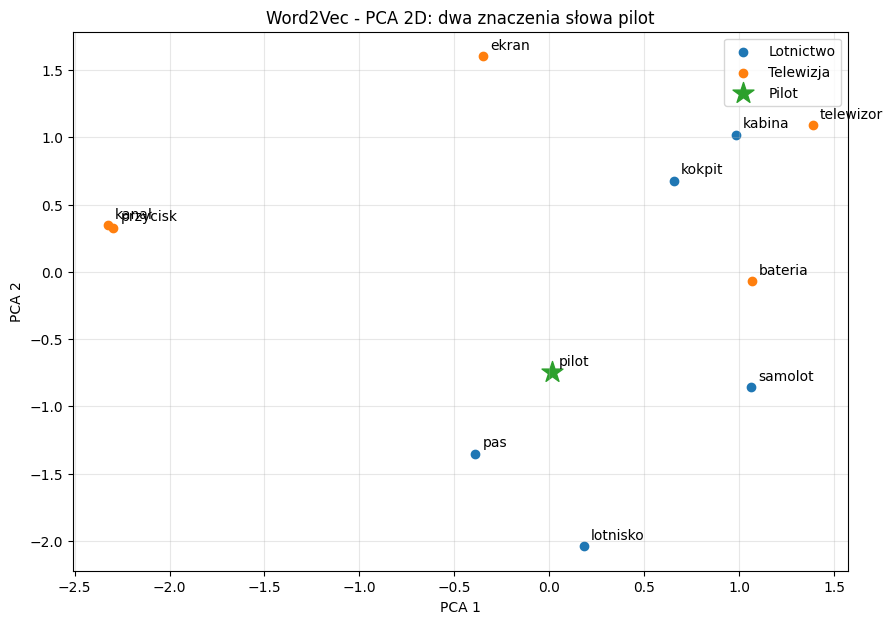

In [11]:
# Grupy tematyczne
grupa_lotnictwo = [
    "samolot",
    "kokpit",
    "lotnisko",
    "kabina",
    "pas"
]

grupa_telewizja = [
    "telewizor",
    "ekran",
    "przycisk",
    "kanał",
    "bateria"
]

wszystkie_slowa = (
    grupa_lotnictwo
    + grupa_telewizja
    + ["pilot"]
)

# Sprawdzenie obecności słów
for w in wszystkie_slowa:
    assert w in model_A.wv, f"Brak słowa: {w}"

# Wektory Word2Vec
V = np.stack([
    model_A.wv[w] for w in wszystkie_slowa
])

# Redukcja do dwóch wymiarów
XY = PCA(
    n_components=2,
    random_state=0
).fit_transform(V)

# Wykres
plt.figure(figsize=(10, 7))

n1 = len(grupa_lotnictwo)
n2 = len(grupa_telewizja)

plt.scatter(
    XY[:n1, 0],
    XY[:n1, 1],
    label="Lotnictwo"
)

plt.scatter(
    XY[n1:n1+n2, 0],
    XY[n1:n1+n2, 1],
    label="Telewizja"
)

plt.scatter(
    XY[-1, 0],
    XY[-1, 1],
    marker="*",
    s=250,
    label="Pilot"
)

for i, w in enumerate(wszystkie_slowa):
    plt.annotate(
        w,
        (XY[i, 0], XY[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Word2Vec - PCA 2D: dwa znaczenia słowa pilot")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [12]:
def podobienstwo_wewnatrz(model, grupa):
    wartosci = []

    for i in range(len(grupa)):
        for j in range(i + 1, len(grupa)):

            p = model.wv.similarity(
                grupa[i], grupa[j]
            )

            wartosci.append(p)

    return np.mean(wartosci)


def podobienstwo_miedzy(model, grupa1, grupa2):
    wartosci = []

    for w1 in grupa1:
        for w2 in grupa2:

            p = model.wv.similarity(w1, w2)
            wartosci.append(p)

    return np.mean(wartosci)


s1 = podobienstwo_wewnatrz(
    model_A, grupa_lotnictwo
)

s2 = podobienstwo_wewnatrz(
    model_A, grupa_telewizja
)

s3 = podobienstwo_miedzy(
    model_A,
    grupa_lotnictwo,
    grupa_telewizja
)

print("ŚREDNIE PODOBIEŃSTWO COSINUSOWE\n")

print(f"Lotnictwo: {s1:.4f}")
print(f"Telewizja: {s2:.4f}")
print(f"Między grupami: {s3:.4f}")

print("\nPRZYKŁADOWE PARY SŁÓW\n")

pary = [
    ("samolot", "kokpit"),
    ("telewizor", "ekran"),
    ("samolot", "telewizor"),
    ("lotnisko", "przycisk")
]

for w1, w2 in pary:
    p = model_A.wv.similarity(w1, w2)

    print(
        f"{w1:12s} - {w2:12s}: {p:.4f}"
    )


ŚREDNIE PODOBIEŃSTWO COSINUSOWE

Lotnictwo: 0.4015
Telewizja: 0.4790
Między grupami: 0.4037

PRZYKŁADOWE PARY SŁÓW

samolot      - kokpit      : 0.4986
telewizor    - ekran       : 0.5422
samolot      - telewizor   : 0.4569
lotnisko     - przycisk    : 0.3269


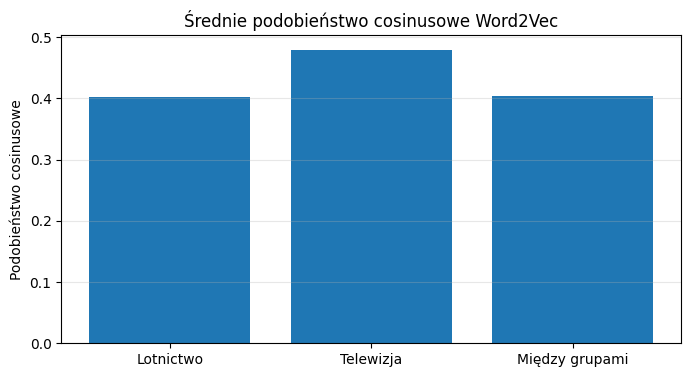

In [13]:
nazwy = [
    "Lotnictwo",
    "Telewizja",
    "Między grupami"
]

wartosci = [s1, s2, s3]

plt.figure(figsize=(8, 4))

plt.bar(nazwy, wartosci)

plt.title("Średnie podobieństwo cosinusowe Word2Vec")
plt.ylabel("Podobieństwo cosinusowe")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [14]:
print("PODSUMOWANIE LABORATORIUM 5")
print("=" * 45)

print("\n1. KORPUS")
print("Liczba zdań:", len(KORPUS))
print("Badane słowo: pilot")
print("Znaczenia: lotnictwo i telewizja")

print("\n2. BPE")

for limit, tok in tokenizery.items():
    sr_w, unk_w = statystyki_bpe(tok, WIDZIANE)
    sr_n, unk_n = statystyki_bpe(tok, NIEWIDZIANE)

    print(
        f"Limit {limit}, słownik {tok.get_vocab_size()}: "
        f"widziane {sr_w:.2f}, niewidziane {sr_n:.2f}; "
        f"UNK {unk_w}/{unk_n}"
    )

print("\n3. WORD2VEC")

print("Wariant A:")
for w, p in sasiedzi_A:
    print(w, round(p, 4))

print("\nWariant B:")
for w, p in sasiedzi_B:
    print(w, round(p, 4))

print("\n4. PODOBIEŃSTWA COSINUSOWE")
print("Lotnictwo:", round(float(s1), 4))
print("Telewizja:", round(float(s2), 4))
print("Między grupami:", round(float(s3), 4))

print("\nZakończono analizę.")


PODSUMOWANIE LABORATORIUM 5

1. KORPUS
Liczba zdań: 60
Badane słowo: pilot
Znaczenia: lotnictwo i telewizja

2. BPE
Limit 80, słownik 80: widziane 3.67, niewidziane 5.67; UNK 0/0
Limit 160, słownik 160: widziane 1.11, niewidziane 3.56; UNK 0/0
Limit 320, słownik 320: widziane 1.00, niewidziane 3.44; UNK 0/0

3. WORD2VEC
Wariant A:
jest 0.593
a 0.5614
kokpit 0.5092
do 0.508
obserwuje 0.4854

Wariant B:
jest 0.5447
który 0.501
przycisk 0.4862
kanał 0.484
kliknięciem 0.4695

4. PODOBIEŃSTWA COSINUSOWE
Lotnictwo: 0.4015
Telewizja: 0.479
Między grupami: 0.4037

Zakończono analizę.
